# 10. 동영상 처리와 움직임 검출

## 10.1 동영상 읽기와 프레임 처리

- 동영상은 시간 순서대로 나열된 영상, 즉 **프레임**의 모음이다.
- FPS는 1초에 표시하는 프레임 수다. 처리 속도와 영상 FPS는 다른 값이다.
- `VideoCapture.read()`로 한 프레임씩 읽고 처리한다.
- 반환값 `ret`가 False이면 파일 끝 또는 읽기 실패일 수 있다.
- 작업이 끝나면 `release()`로 파일과 장치를 닫는다.

이번에는 고정 배경 위에서 사각형이 이동하고 멈추는 합성 영상을 만든다. 실제 촬영의 조명 변화·그림자·카메라 흔들림을 모두 재현한 영상은 아니다.

### 셀 1. 준비와 합성 동영상 저장

노트북을 실습 폴더에서 열고 위에서부터 실행한다. 필요한 패키지는 OpenCV, NumPy, Matplotlib이다. AVI는 OpenCV 읽기 실습용이며 브라우저에서 바로 재생되지 않을 수 있다. 별도 GIF 미리보기도 포함한다.

In [1]:
# 셀 1: 합성 동영상 생성
# 배경만 있는 구간, 물체가 이동하는 구간, 정지하는 구간을 포함한 100프레임을 만든다.

# Path는 운영체제에 맞게 파일 경로를 조합하는 데 사용한다.
from pathlib import Path
import json
# OpenCV는 영상 처리, NumPy는 배열 계산, Matplotlib은 결과 시각화에 사용한다.
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
# 현재 작업 폴더를 기준으로 assets를 찾는다. 노트북은 각 장의 폴더에서 실행한다.
ROOT=Path.cwd();ASSETS=ROOT/'assets';ASSETS.mkdir(exist_ok=True)
W,H,FPS,N=320,200,20,100
# 프레임 0~19: 배경만, 20~59: 이동, 60~99: 같은 위치에서 정지
xgrid=np.linspace(40,80,W,dtype=np.uint8)
background=np.repeat(xgrid[None,:,None],H,axis=0).repeat(3,axis=2)
frames=[];truth=[]
for t in range(N):
    frame=background.copy();gt=np.zeros((H,W),np.uint8)
    if t>=20:
        x=20+4*min(t-20,39);y=80
        # 오른쪽 아래 좌표도 포함해 그린다. 폭·높이에서 1을 빼면 지정한 픽셀 범위와 맞는다.
        cv2.rectangle(frame,(x,y),(x+39,y+29),(30,180,230),-1)
        gt[y:y+30,x:x+40]=255
    frames.append(frame);truth.append(gt)
video_path=ASSETS/'synthetic_motion.avi'
# MJPG 코덱, FPS, (너비, 높이)를 지정하고 같은 크기의 BGR 프레임을 기록한다.
writer=cv2.VideoWriter(str(video_path),cv2.VideoWriter_fourcc(*'MJPG'),FPS,(W,H))
if not writer.isOpened():raise RuntimeError('MJPG VideoWriter를 열 수 없습니다.')
try:
    for frame in frames:writer.write(frame)
finally:writer.release()
preview=[Image.fromarray(cv2.cvtColor(f,cv2.COLOR_BGR2RGB)) for f in frames[::2]]
preview[0].save(ASSETS/'motion_preview.gif',save_all=True,append_images=preview[1:],duration=100,loop=0)
print('저장:',video_path.name,'프레임:',N,'FPS:',FPS)

# 비교 그림의 배치를 통일하고, 영상 또는 결과 배열을 화면에 표시한다.
def show(items,name):
    fig,axs=plt.subplots(1,len(items),figsize=(4*len(items),4),squeeze=False)
    for ax,(title,img) in zip(axs.flat,items):
        if img.ndim==2:ax.imshow(img,cmap='gray',vmin=0,vmax=255)
        else:ax.imshow(cv2.cvtColor(img,cv2.COLOR_BGR2RGB))
        ax.set_title(title);ax.axis('off')
    fig.tight_layout();fig.savefig(ASSETS/name,dpi=140);plt.show();plt.close(fig)

저장: synthetic_motion.avi 프레임: 100 FPS: 20


### 셀 2. 저장한 파일을 다시 읽기

코덱을 거친 영상을 실제로 읽어서 처리한다. MJPEG는 손실 압축이므로 생성 배열과 읽은 픽셀이 완전히 같지는 않을 수 있다. 짧은 실습이므로 모든 프레임을 저장하지만, 긴 동영상은 프레임 하나씩 처리하고 필요한 이전 프레임만 유지한다.

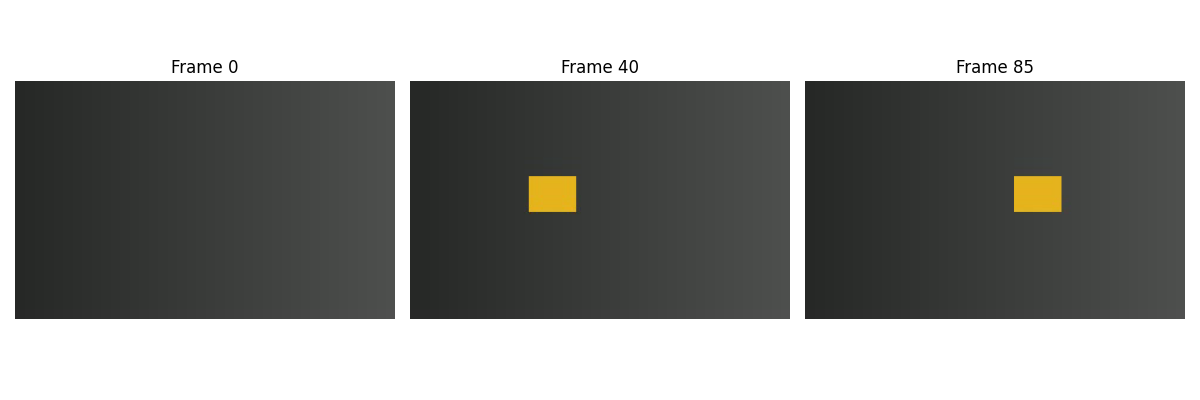

실제 읽은 프레임: 100 기록 FPS: 20.0


In [2]:
# 셀 2: 동영상 읽기
# VideoCapture로 끝까지 읽으며 반환값으로 종료를 판단하고 마지막에 자원을 해제한다.

# 파일 경로로 동영상을 열고 isOpened로 읽기 가능 여부를 확인한다.
capture=cv2.VideoCapture(str(video_path))
if not capture.isOpened():raise FileNotFoundError(video_path)
read_frames=[]
try:
    read_fps=capture.get(cv2.CAP_PROP_FPS)
    while True:
        # ret이 False면 다음 프레임을 얻지 못한 상태이므로 읽기를 종료한다.
        ret,frame=capture.read()
        if not ret:break
        read_frames.append(frame)
finally:capture.release()
assert len(read_frames)==N
assert all(f.shape==(H,W,3) for f in read_frames)
print('실제 읽은 프레임:',len(read_frames),'기록 FPS:',read_fps)
show([(f'Frame {t}',read_frames[t]) for t in [0,40,85]],'frames.png')

## 10.2 차영상 (Difference Image)

### 프레임 간 차이

$$D_t(x,y)=|I_t(x,y)-I_{t-1}(x,y)|$$

- 직전 프레임 이후 바뀐 곳을 강조한다.
- 물체가 조금 움직이면 겹친 내부는 변하지 않아 이동 경계만 나타날 수 있다.
- 물체가 멈추면 변화가 없어서 사라질 수 있다.

### 기준 배경 영상과의 차이

$$D_{B,t}(x,y)=|I_t(x,y)-B(x,y)|$$

- 물체가 없는 기준 배경 B와 현재 영상을 비교한다.
- 물체가 정지해도 배경과 다르면 검출할 수 있다.
- 조명이나 배경 자체가 바뀌면 오검출이 생길 수 있다.
- 첫 프레임에 물체가 있으면 그것도 배경에 포함되므로 첫 프레임이 항상 좋은 기준은 아니다.

차이는 `cv2.absdiff()`로 계산한다. `uint8` NumPy 배열을 그대로 빼면 음수가 순환하여 잘못된 결과가 생길 수 있다.

### 셀 3. 이동·정지 시점의 차영상

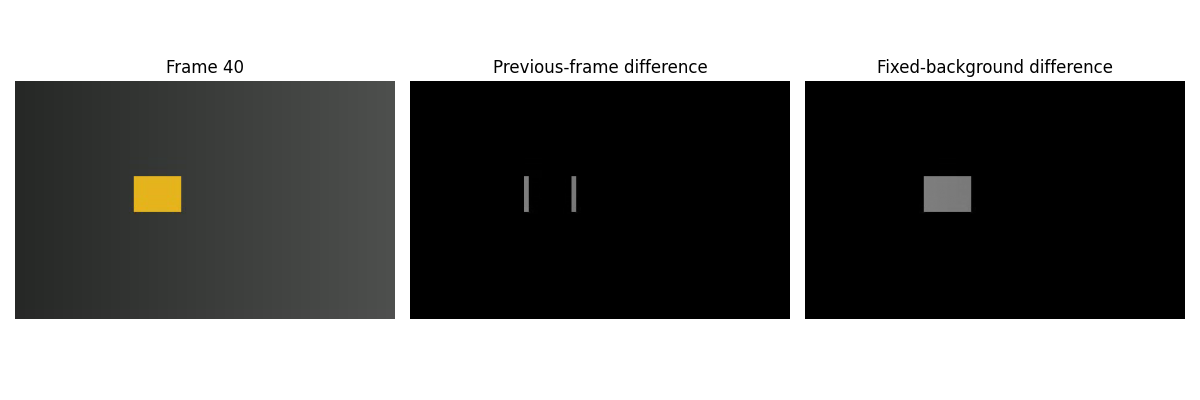

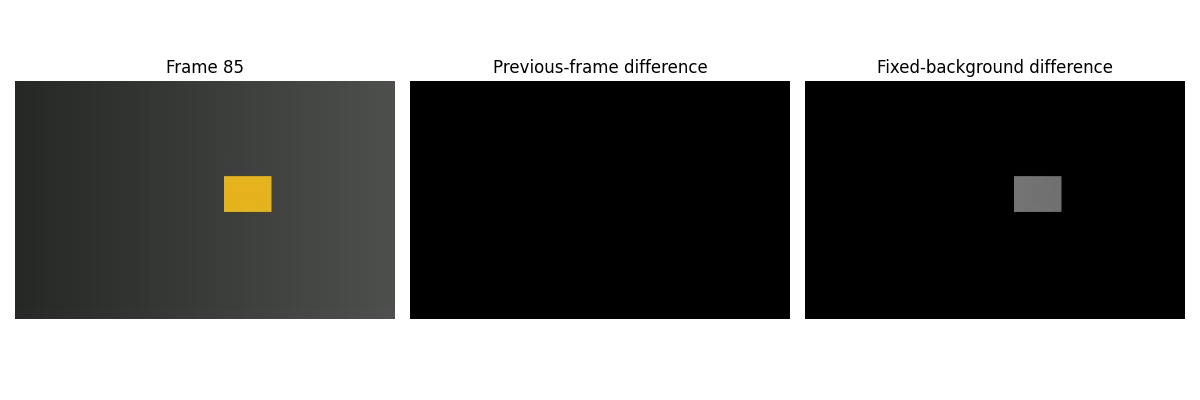

정지 시점의 프레임 차이 최댓값: 0


In [3]:
# 셀 3: 프레임 차이와 고정 배경 차이
# 직전 프레임과의 변화, 최초 빈 배경과의 차이를 각각 계산한다.

# B·G·R을 밝기 가중합으로 바꾸어 단일 채널 영상으로 만든다.
grays=[cv2.cvtColor(f,cv2.COLOR_BGR2GRAY) for f in read_frames]
# 첫 프레임은 물체가 없는 배경으로 생성했으므로 고정 배경 기준으로 사용한다.
reference=grays[0]
frame_diffs=[np.zeros_like(reference)]
for i in range(1,N):frame_diffs.append(cv2.absdiff(grays[i],grays[i-1]))
# absdiff는 두 uint8 영상의 절대 차이를 계산하여 음수 순환을 피한다.
background_diffs=[cv2.absdiff(g,reference) for g in grays]
for t in [40,85]:
    show([(f'Frame {t}',read_frames[t]),('Previous-frame difference',frame_diffs[t]),
          ('Fixed-background difference',background_diffs[t])],f'difference_{t}.png')
print('정지 시점의 프레임 차이 최댓값:',int(frame_diffs[85].max()))

## 10.3 배경 차분 (Background Subtraction)

### MOG2와 KNN

| 방법 | 배경을 표현하는 관점 |
| :---: | :---: |
| MOG2 | 픽셀 값 분포를 여러 가우시안 성분으로 모델링 |
| KNN | 과거에 관측한 표본들과의 근접성을 이용 |

고정 배경과의 단순 뺄셈과 달리 배경 모델을 시간에 따라 갱신한다. 이번에는 MOG2를 사용한다.

- `history`: 배경 모델의 이력에 관련된 설정. 정확히 해당 프레임이 지나면 물체가 사라지는 타이머가 아니다.
- `varThreshold`: 모델과 관측의 일치 판단에 쓰는 제곱 마할라노비스 거리 임계값. 원래 밝기 차이 임계값이 아니다.
- `learningRate`: 갱신 속도. 0은 갱신 중지, 음수는 자동 선택이다.
- 모델은 프레임 루프 밖에서 한 번 만들고 순서대로 갱신한다.
- 재실행할 때는 새 모델을 만들어야 초기 상태에서 비교할 수 있다.

그림자 검출을 켜면 기본 마스크 값은 배경 0, 그림자 후보 127, 전경 255다. 그림자 판정이 항상 정확한 것은 아니다.

### 셀 4. 갱신 모델과 고정 모델 비교

처음 20프레임으로 빈 배경을 학습한다. 이후 하나는 갱신하고, 다른 하나는 학습을 멈춘다. 정지 물체가 배경으로 흡수되는 현상은 학습률과 장면에 따라 달라진다.

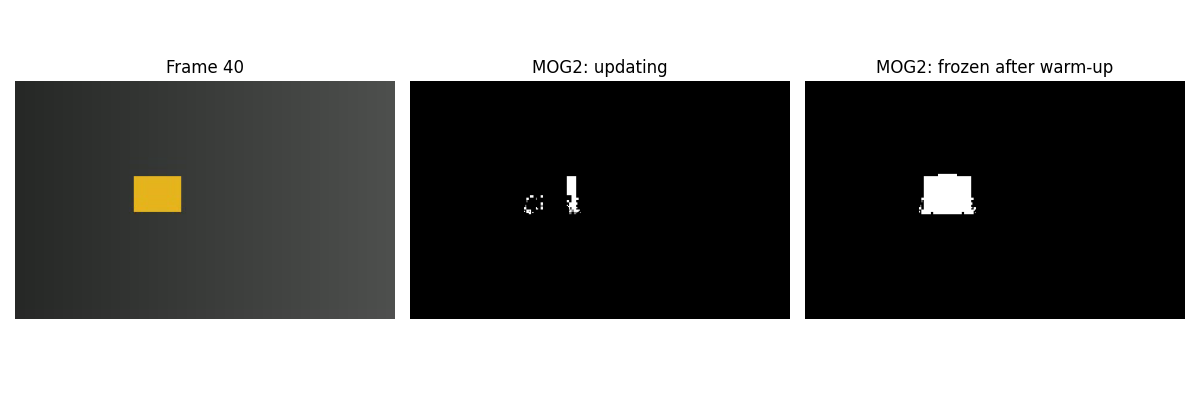

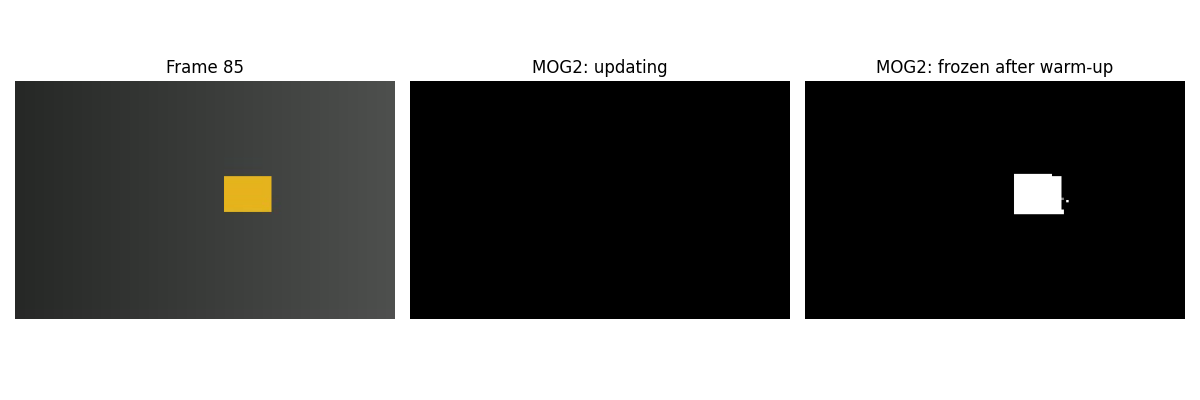

초기 프레임은 배경 학습 중이므로 검출 평가에서 제외합니다.


In [4]:
# 셀 4: MOG2 배경 모델 비교
# 계속 학습하는 모델과 초기 학습 이후 갱신을 멈춘 모델의 정지 물체 반응을 비교한다.

# varThreshold=16은 배경 성분과의 거리 판정 기준이며, 그림자는 기본값 127로 별도 표시된다.
adaptive=cv2.createBackgroundSubtractorMOG2(history=100,varThreshold=16,detectShadows=True)
# varThreshold=16은 배경 성분과의 거리 판정 기준이며, 그림자는 기본값 127로 별도 표시된다.
frozen=cv2.createBackgroundSubtractorMOG2(history=100,varThreshold=16,detectShadows=True)
adaptive_masks=[];frozen_masks=[]
for t,frame in enumerate(read_frames):
    # 초기 20프레임은 0.1로 학습하고 이후에도 0.05로 갱신해 정지 물체가 배경에 흡수될 수 있다.
    adaptive_masks.append(adaptive.apply(frame,learningRate=.1 if t<20 else .05))
    # 초기 학습 후 learningRate=0으로 고정하여 기준 배경을 더 이상 갱신하지 않는다.
    frozen_masks.append(frozen.apply(frame,learningRate=.1 if t<20 else 0))
for t in [40,85]:
    show([(f'Frame {t}',read_frames[t]),('MOG2: updating',adaptive_masks[t]),
          ('MOG2: frozen after warm-up',frozen_masks[t])],f'mog2_{t}.png')
print('초기 프레임은 배경 학습 중이므로 검출 평가에서 제외합니다.')

## 10.4 전경 마스크 후처리

### 이진화

$$M(x,y)=\begin{cases}255,&D(x,y)>\tau\\0,&\text{그 외}\end{cases}$$

- 차영상은 밝기 차이가 임계값보다 큰 곳을 전경으로 만든다.
- MOG2의 기본 그림자 값 127을 제외하려면 255만 선택한다.
- MOG2에 `raw > 0`을 적용하면 그림자 후보까지 전경에 들어간다.

### 형태학적 처리

- 열림: 작은 흰 잡음을 줄일 수 있다.
- 닫힘: 작은 검은 구멍·틈을 메울 수 있다.
- 큰 커널은 작은 실제 물체를 지우거나 가까운 물체를 합칠 수 있다.
- 아래의 3×3, 5×5는 이 실습용 설정이다.

### 셀 5. 이진 마스크와 후처리

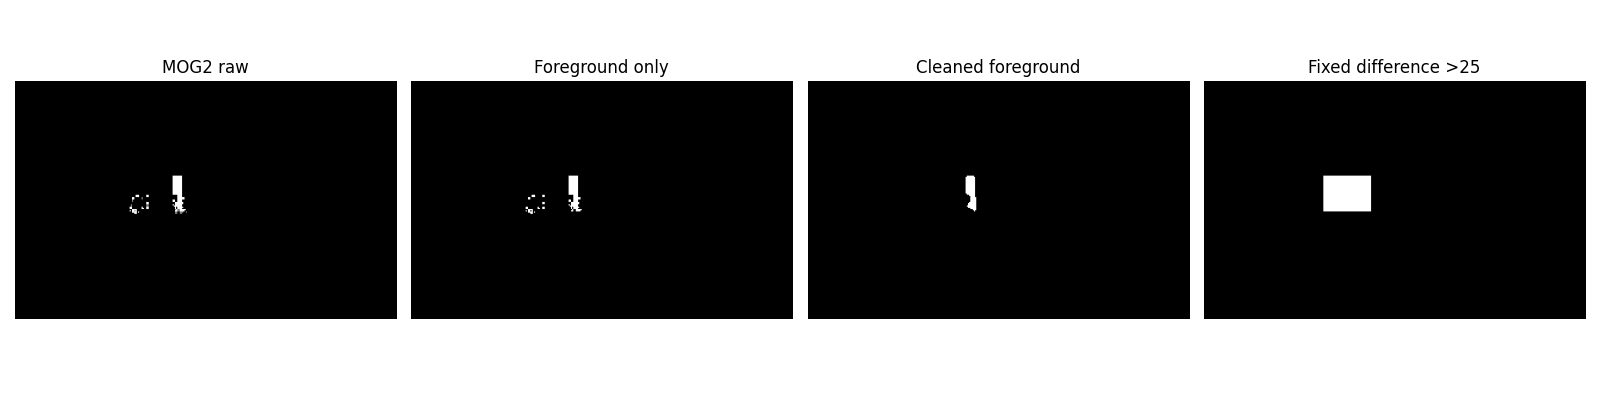

In [5]:
# 셀 5: 전경 마스크 후처리
# MOG2에서 확실한 전경 255만 남기고 열림·닫힘으로 작은 점과 틈을 정리한다.

kopen=cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(3,3))
kclose=cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(5,5))
def cleanup(binary):
    # 침식 다음 팽창을 적용하여 구조 요소보다 작은 밝은 구조를 줄인다.
    opened=cv2.morphologyEx(binary,cv2.MORPH_OPEN,kopen)
    return cv2.morphologyEx(opened,cv2.MORPH_CLOSE,kclose)
clean_masks=[]
for raw in adaptive_masks:
    # 배경 0과 그림자 127을 제외하고 전경으로 분류된 255만 유지한다.
    binary=np.where(raw==255,255,0).astype(np.uint8)
    clean_masks.append(cleanup(binary))
t=40
_,fixed_binary=cv2.threshold(background_diffs[t],25,255,cv2.THRESH_BINARY)
show([('MOG2 raw',adaptive_masks[t]),('Foreground only',(adaptive_masks[t]==255).astype(np.uint8)*255),
      ('Cleaned foreground',clean_masks[t]),('Fixed difference >25',fixed_binary)],'cleanup.png')
assert all(set(np.unique(m)).issubset({0,255}) for m in clean_masks)

## 10.5 움직이는 영역 표시

- `findContours()`로 흰 영역의 외곽선을 찾는다.
- `contourArea()`로 작은 영역을 제외한다.
- `boundingRect()`로 영역을 감싸는 사각형을 얻는다.
- 면적 임계값은 제곱픽셀 단위이며 영상 해상도에 영향을 받는다.
- 외곽선 면적과 흰 픽셀 개수는 정의가 달라 정확히 같지는 않다.
- 한 물체가 여러 영역으로 나뉘거나 여러 물체가 하나로 합쳐질 수 있다.
- 이 단계는 매 프레임의 영역 검출이며 같은 물체에 ID를 유지하는 추적은 아니다.

### 셀 6. 경계 상자와 결과 동영상

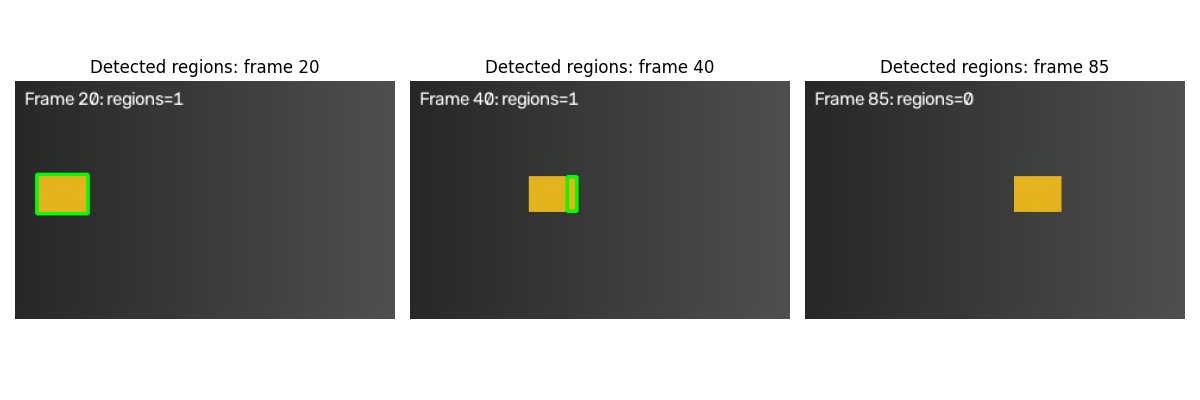

영상·GIF 저장 완료


In [6]:
# 셀 6: 움직이는 영역 표시와 영상 저장
# 전경 외곽선에서 작은 영역을 제외하고 경계 상자를 그린 프레임을 저장한다.

annotated=[];counts=[];boxes_per_frame=[]
for t,(frame,mask) in enumerate(zip(read_frames,clean_masks)):
    canvas=frame.copy();boxes=[]
    if t>=20:  # 초기 배경 학습 구간 제외
        # 바깥 외곽선만 추출하고 직선 구간의 중간 점을 줄여 저장한다.
        contours,_=cv2.findContours(mask,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
        for contour in contours:
            # 너무 작은 외곽선은 잡음 후보로 제외한다. 외곽선 면적은 흰 픽셀 수와 완전히 같지 않다.
            if cv2.contourArea(contour)<100:continue
            # 외곽선을 둘러싸는 축 정렬 사각형의 왼쪽 위 좌표와 폭·높이를 얻는다.
            x,y,w,h=cv2.boundingRect(contour)
            boxes.append([int(x),int(y),int(w),int(h)])
            # 오른쪽 아래 좌표도 포함해 그린다. 폭·높이에서 1을 빼면 지정한 픽셀 범위와 맞는다.
            cv2.rectangle(canvas,(x,y),(x+w-1,y+h-1),(0,255,0),2)
    cv2.putText(canvas,f'Frame {t}: regions={len(boxes)}',(8,20),cv2.FONT_HERSHEY_SIMPLEX,.5,(255,255,255),1)
    annotated.append(canvas);counts.append(len(boxes));boxes_per_frame.append(boxes)
show([(f'Detected regions: frame {t}',annotated[t]) for t in [20,40,85]],'detections.png')
# MJPG 코덱, FPS, (너비, 높이)를 지정하고 같은 크기의 BGR 프레임을 기록한다.
writer=cv2.VideoWriter(str(ASSETS/'motion_detection.avi'),cv2.VideoWriter_fourcc(*'MJPG'),FPS,(W,H))
if not writer.isOpened():raise RuntimeError('결과 VideoWriter 생성 실패')
try:
    for frame in annotated:writer.write(frame)
finally:writer.release()
gif=[Image.fromarray(cv2.cvtColor(f,cv2.COLOR_BGR2RGB)) for f in annotated[::2]]
gif[0].save(ASSETS/'detection_preview.gif',save_all=True,append_images=gif[1:],duration=100,loop=0)
print('영상·GIF 저장 완료')

### 셀 7. 차이와 한계 검증

정지한 사각형도 화면에는 존재하지만 ‘최근 변화’와 ‘갱신된 배경에서 벗어난 영역’이라는 기준에서는 검출되지 않을 수 있다. 아래 그래프는 픽셀 개수를 비교할 뿐 물체 인식 정확도를 의미하지 않는다.

합성 이동 구간에서는 생성 시의 정답 마스크와 IoU를 계산한다. 이 단순 실험의 수치를 실제 CCTV 성능으로 해석하지 않는다.

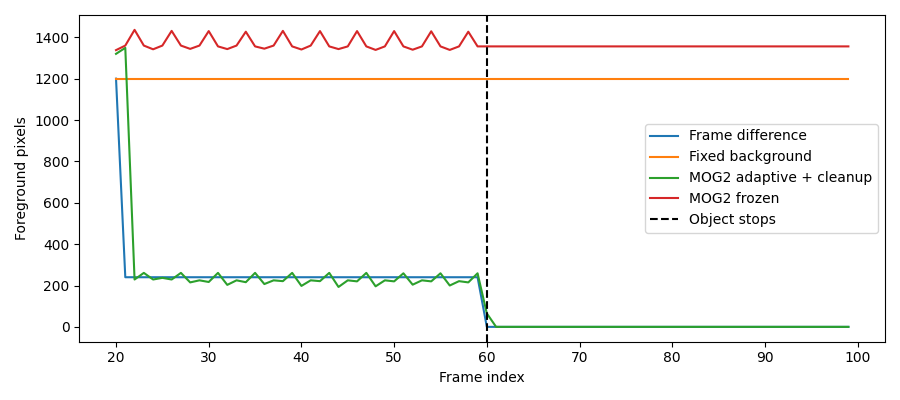

{
  "opencv": "5.0.0",
  "frames_read": 100,
  "output_frames_read": 100,
  "synthetic_moving_interval_mean_iou": 0.2068252052081892,
  "frame85_pixels": {
    "frame_difference": 0,
    "fixed_background": 1200,
    "mog2_adaptive": 0,
    "mog2_frozen": 1356
  }
}


In [7]:
# 셀 7: 검출 반응과 합성 정답 평가
# 정지 전후 전경 수, 이동 구간 마스크 IoU, 결과 영상의 프레임 수를 확인한다.

def count_foreground(ms):return [int(np.count_nonzero(m)) for m in ms]
fd_binary=[(d>25).astype(np.uint8)*255 for d in frame_diffs]
bg_binary=[(d>25).astype(np.uint8)*255 for d in background_diffs]
fr_binary=[(m==255).astype(np.uint8)*255 for m in frozen_masks]
fig,ax=plt.subplots(figsize=(9,4))
for name,ms in [('Frame difference',fd_binary),('Fixed background',bg_binary),('MOG2 adaptive + cleanup',clean_masks),('MOG2 frozen',fr_binary)]:
    ax.plot(range(20,N),count_foreground(ms)[20:],label=name)
ax.axvline(60,color='black',linestyle='--',label='Object stops')
ax.set(xlabel='Frame index',ylabel='Foreground pixels');ax.legend();fig.tight_layout()
fig.savefig(ASSETS/'comparison.png',dpi=140);plt.show();plt.close(fig)
ious=[]
for t in range(20,60):
    # 후처리한 예측 마스크와 합성 영상 생성 때 기록한 정답을 불리언 영역으로 비교한다.
    pred=clean_masks[t]>0;gt=truth[t]>0
    # 전경 예측과 합성 정답의 교집합 픽셀 수를 합집합 픽셀 수로 나누어 IoU를 구한다.
    ious.append(float(np.count_nonzero(pred & gt)/np.count_nonzero(pred|gt)))
assert np.count_nonzero(fd_binary[85])==0
assert np.count_nonzero(bg_binary[85])>0
check=cv2.VideoCapture(str(ASSETS/'motion_detection.avi'));decoded=0
try:
    while True:
        ok,_=check.read()
        if not ok:break
        decoded+=1
finally:check.release()
assert decoded==N
summary={'opencv':cv2.__version__,'frames_read':len(read_frames),'output_frames_read':decoded,
         'synthetic_moving_interval_mean_iou':float(np.mean(ious)),
         'frame85_pixels':{'frame_difference':int(np.count_nonzero(fd_binary[85])),
                           'fixed_background':int(np.count_nonzero(bg_binary[85])),
                           'mog2_adaptive':int(np.count_nonzero(clean_masks[85])),
                           'mog2_frozen':int(np.count_nonzero(fr_binary[85]))}}
# 수치 결과를 UTF-8 JSON으로 저장하여 그림과 별도로 확인할 수 있게 한다.
(ROOT/'results.json').write_text(json.dumps(summary,indent=2),encoding='utf-8')
# 수치 결과를 UTF-8 JSON으로 저장하여 그림과 별도로 확인할 수 있게 한다.
(ROOT/'bounding_boxes.json').write_text(json.dumps(boxes_per_frame),encoding='utf-8')
print(json.dumps(summary,indent=2))

### 실제 동영상에 적용할 때

| 상황 | 예상 문제 |
| :---: | :---: |
| 카메라 흔들림 | 영상 전체의 차이가 생김; 안정화 등이 필요 |
| 급격한 조명 변화 | 배경도 전경으로 판정될 수 있음 |
| 나뭇잎·물결 | 반복적인 배경 움직임이 남을 수 있음 |
| 오래 정지한 물체 | 갱신 모델에 배경으로 흡수될 수 있음 |
| 그림자·반사 | 실제 물체와 다른 영역이 검출될 수 있음 |
| 작은 물체 | 형태학·면적 필터에 의해 제거될 수 있음 |

실제 파일은 셀 2의 VideoCapture 경로를 바꿔 읽을 수 있지만, 이번 코드의 20프레임 준비 구간·정답 마스크·검증문은 합성 영상 전용이므로 그대로 적용하면 안 된다. 입력에 맞게 처리 구간과 평가 방식을 조정한다. 긴 영상은 모든 프레임을 리스트에 담지 않고 읽기·처리·쓰기를 한 루프에서 수행한다.

## 참고 문서

- [OpenCV — Background Subtraction](https://docs.opencv.org/4.x/d1/dc5/tutorial_background_subtraction.html)

동영상은 포함된 코드로 생성한 교육용 합성 데이터다. 마스크 비교는 같은 디코딩 프레임을 사용한다.


## 실행 검증 범위

동일한 Python 실행 공간에서 코드 셀을 순차 실행하고 결과를 저장했다. 실제 Jupyter 커널의 Run All은 검증하지 않았다. 입력·출력 AVI의 100프레임 읽기와 합성 영상의 정지 구간 동작을 확인했다.

## 실험 결과 해석

이 설정에서 이동 구간 MOG2 후처리 마스크의 평균 IoU는 약 0.207이다. 학습률 0.05로 빠르게 갱신하면 사각형 전체가 계속 전경으로 유지되지 않고 일부가 배경에 흡수되어 마스크가 불완전해질 수 있다. 이 실험은 높은 검출 성능을 보장하는 설정이 아니라 갱신 효과와 한계를 보여준다. 프레임 85에서는 프레임 차이와 갱신 MOG2의 전경이 0이지만, 고정 배경 비교는 1,200픽셀을 유지했다. 학습을 멈춘 MOG2는 1,356픽셀로 정답 면적과 달랐으며, 압축·모델 오차도 고려해야 한다.